In [1]:
%cd ..
%reset -f

/home/remi/jul26_bds_blood_cells


PBC : ['BAS', 'EBO', 'EOS', 'IG', 'LYT', 'MMZ', 'MON', 'MYB', 'NEUTROPHIL', 'NGB', 'NGS', 'PLATELET', 'PMO']
LMU : ['BAS', 'EBO', 'EOS', 'KSC', 'LYA', 'LYT', 'MMZ', 'MOB', 'MON', 'MYB', 'MYO', 'NGB', 'NGS', 'PMB', 'PMO']


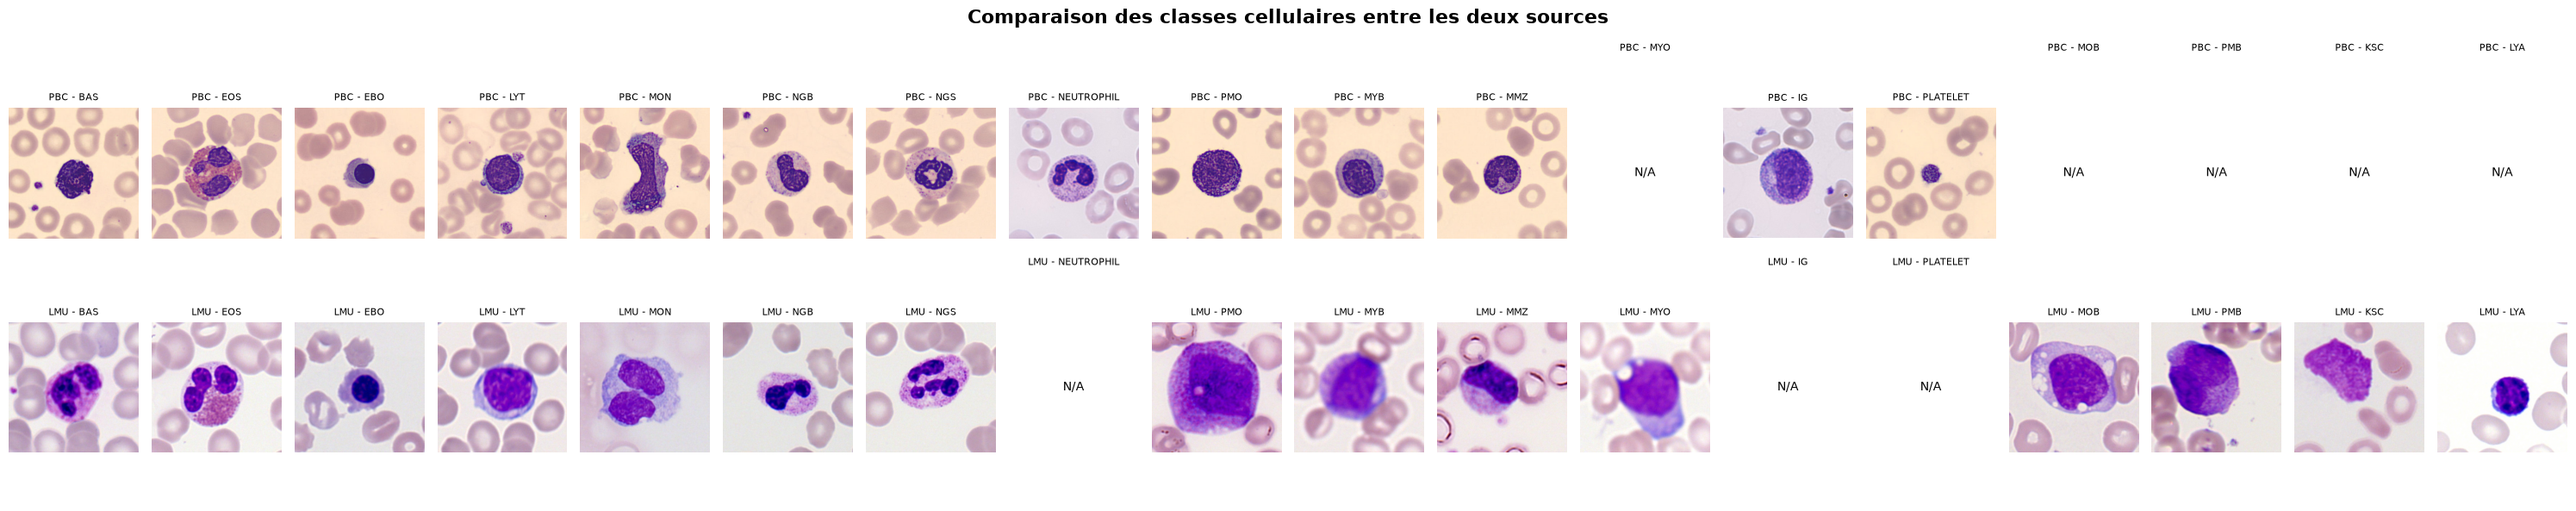

<Figure size 640x480 with 0 Axes>

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
from src.features.common import load_image
from src.cfg import MAPPING, IMAGE_EXTENSIONS, MUNICH_DIR, BARCELONA_DIR

PBC_ROOT = BARCELONA_DIR
LMU_ROOT = MUNICH_DIR

classes = list(dict.fromkeys(MAPPING["class_code"].values()))

def get_class_from_filename(path):
    code = path.stem.split("_")[0].upper()

    # Mapping des codes connus
    if code in MAPPING["class_code"]:
        return MAPPING["class_code"][code]

    # Certains fichiers utilisent directement le nom de la classe cible
    if code in MAPPING["class_code"].values():
        return code

    return None

def get_images_by_class(root):
    images = {}

    for path in sorted(root.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        class_name = get_class_from_filename(path)

        if class_name is None:
            continue

        # On conserve le premier fichier trouvé pour chaque classe
        if class_name not in images:
            images[class_name] = path

    return images

pbc_images = get_images_by_class(PBC_ROOT)
lmu_images = get_images_by_class(LMU_ROOT)

print("PBC :", sorted(pbc_images.keys()))
print("LMU :", sorted(lmu_images.keys()))

fig, axes = plt.subplots(2, len(classes), figsize=(30, 6))

for col, class_name in enumerate(classes):

    for row, (source_name, images) in enumerate([
        ("PBC", pbc_images),
        ("LMU", lmu_images)
    ]):

        ax = axes[row, col]
        ax.axis("off")

        image_path = images.get(class_name)

        if image_path is not None:
            ax.imshow(load_image(image_path))
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=10)

        ax.set_title(f"{source_name} - {class_name}", fontsize=8)

axes[0, 0].set_ylabel(
    "Barcelona / PBC",
    fontsize=11,
    fontweight="bold"
)

axes[1, 0].set_ylabel(
    "Munich / LMU",
    fontsize=11,
    fontweight="bold"
)

fig.suptitle(
    "Comparaison des classes cellulaires entre les deux sources",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
from src.features.transform import *
from src.features.common import load_image

reference_munich = load_image("data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0008.tiff")
reference_barcelona = load_image("data/PBC_dataset_normal_DIB/basophil/BA_20161.jpg")


experiments = {
    "baseline": [Compose([Resize((224, 224)),ToFloat32()], label=0),
                 Compose([Resize((224, 224)),ToFloat32()], label=1)],
    "crop": [Compose([Crop(),Resize((224, 224)),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "histogram equalization": [Compose([Crop(),Resize((224, 224)),HistogramEqualization(),ToFloat32()], label=0),
                              Compose([Crop(),Resize((224, 224)),HistogramEqualization(),ToFloat32()], label=1)],
    "clahe": [Compose([Crop(),Resize((224, 224)),Clahe(),ToFloat32()], label=0),
              Compose([Crop(),Resize((224, 224)),Clahe(),ToFloat32()], label=1)],
    "reinhard": [Compose([Crop(),Resize((224, 224)),Reinhard(reference_munich),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "macenko": [Compose([Crop(),Resize((224, 224)),Macenko(reference_munich),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "coral": [Compose([Crop(),Resize((224, 224)),Coral(reference_munich),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "vahadane": [Compose([Crop(),Resize((224, 224)),Vahadane(reference_munich),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "reinhard-coral": [Compose([Crop(),Resize((224, 224)),Reinhard(reference_munich),Coral(reference_munich),ToFloat32()], label=0),
                       Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "reinhard-vahadane": [Compose([Crop(),Resize((224, 224)),Reinhard(reference_munich),Vahadane(reference_munich),ToFloat32()], label=0),
                        Compose([Crop(),Resize((224, 224)),ToFloat32()], label=1)],
    "CenterWeightedImage": [Compose([Crop(),Resize((224, 224)),CenterWeightedImage(),ToFloat32()], label=0),
                 Compose([Crop(),Resize((224, 224)),CenterWeightedImage(),ToFloat32()], label=1)],
    "Compress_Jpeg": [Compose([CompressJpeg(100),Crop(),Resize((224, 224)),ToFloat32()], label=0),
                        Compose([CompressJpeg(100),Crop(),Resize((224, 224)),ToFloat32()], label=1)],
}

2026-08-24 15:55:48.786192: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-24 15:55:48.828939: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-24 15:55:49.666156: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


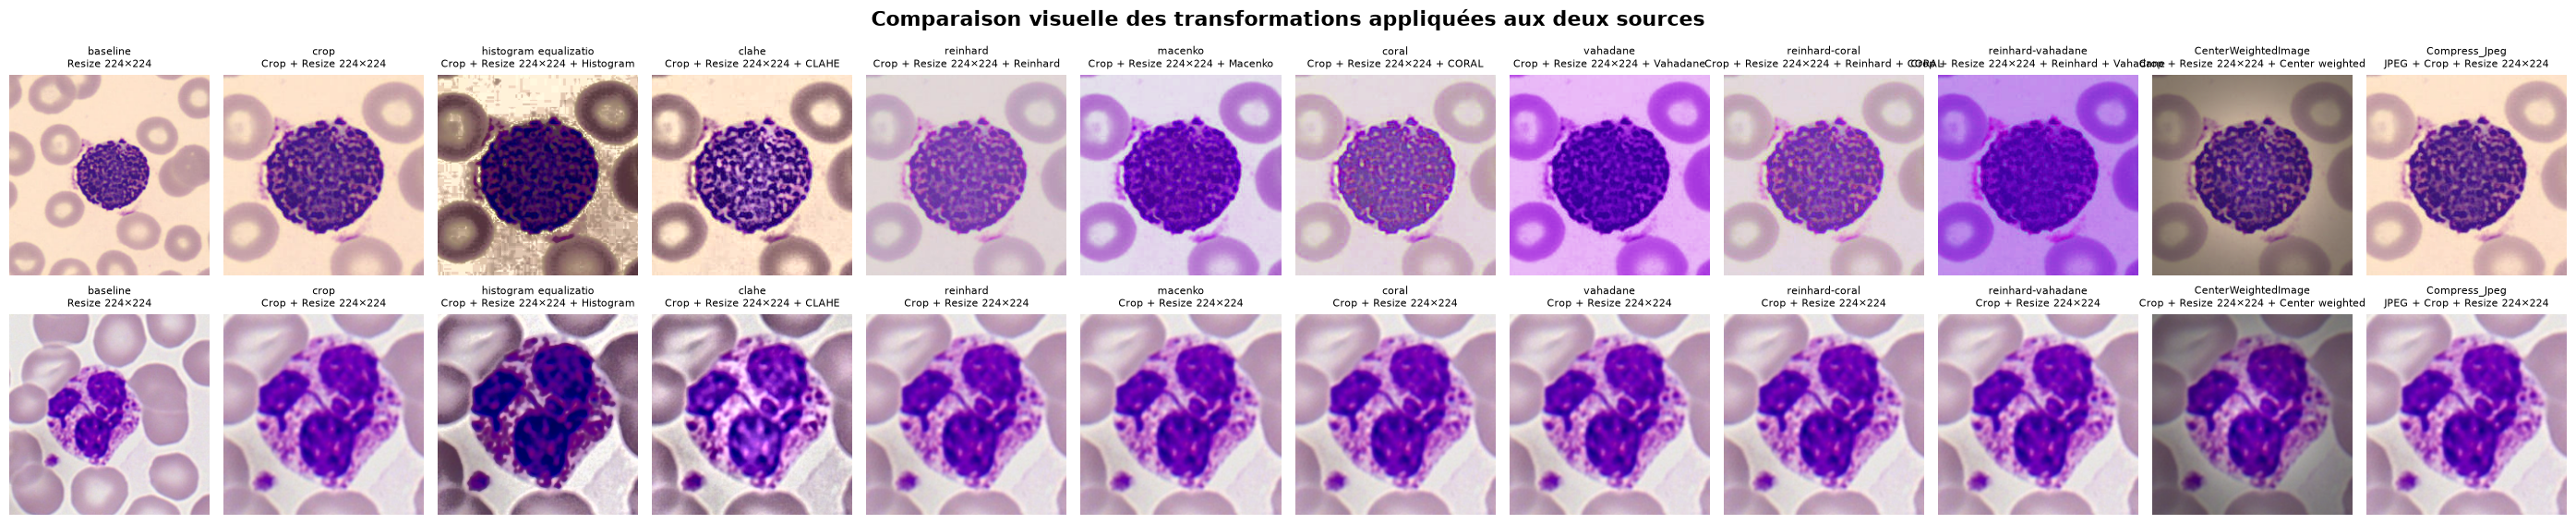

In [5]:
import matplotlib.pyplot as plt
import textwrap

images = {
    "Barcelona / PBC": reference_barcelona,
    "Munich / LMU": reference_munich,
}

def get_transform_names(compose):
    return [type(t).__name__ for t in compose.transforms if type(t).__name__ != "ToFloat32"]

def format_steps(names):
    mapping = {
        "Resize": "Resize 224×224",
        "Crop": "Crop",
        "HistogramEqualization": "Histogram",
        "Clahe": "CLAHE",
        "Reinhard": "Reinhard",
        "Macenko": "Macenko",
        "Coral": "CORAL",
        "Vahadane": "Vahadane",
        "CenterWeightedImage": "Center weighted",
        "CompressJpeg": "JPEG",
    }
    return " + ".join(mapping.get(name, name) for name in names)

fig, axes = plt.subplots(2, len(experiments), figsize=(28, 6))

for col, (experiment_name, pipelines) in enumerate(experiments.items()):
    for row, (source_name, image) in enumerate(images.items()):
        pipeline = pipelines[row]
        transformed = pipeline(image.copy())

        if transformed.dtype != np.uint8:
            transformed = np.clip(transformed, 0, 1)

        axes[row, col].imshow(transformed)
        axes[row, col].axis("off")

        names = get_transform_names(pipeline)
        steps = format_steps(names)

        axes[row, col].set_title(
            f"{experiment_name}\n{steps}",
            fontsize=8
        )

for row, source_name in enumerate(images):
    axes[row, 0].set_ylabel(
        source_name,
        fontsize=11,
        fontweight="bold",
        rotation=90,
        labelpad=15
    )

fig.suptitle(
    "Comparaison visuelle des transformations appliquées aux deux sources",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()